In [16]:
import os
import time
import json
import math
import random
import collections
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

from datasets import load_dataset
from transformers import BertTokenizer, BertForSequenceClassification

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

import matplotlib.pyplot as plt


# ============================================================
# 0. CONFIGURATION
# ============================================================
SEED = 42

TASK_NAME = 'imdb'

# ============================================================
# 1. SETUP
# ============================================================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device: {DEVICE}")

BATCH_TRAIN = 16  # Training batch size
BATCH_TEST = 32  # Test/Validation batch size
EPOCHS_FINETUNE_BASELINE = 1  # Epochs for baseline fine-tuning
RECOVERY_EPOCHS = 1  # Epochs for recovery fine-tuning
LR = 2e-5  # Learning rate
MAX_LEN = 128  # Max sequence length for tokenizer

# Pruning parameters
BETA = 0.9  # Decay factor for exponential moving average (used in GOT)
THRESHOLDS = [0.001]  # Thresholds for pruning (e.g., [0.001, 0.0005])
SCORING_MODE = 'grad_oscillation'  # 'grad_norm' or 'grad_oscillation'
SELECTION_MODE = 'threshold'  # 'threshold' or 'top_k'
USE_STRATIFIED_500 = True  # Whether to use a stratified 500-sample subset for initial pruning analysis

# Output directory
SAVE_DIR = './pruning_results'
os.makedirs(SAVE_DIR, exist_ok=True)

# Set random seeds for reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

start_time = time.time() # Start timing the entire process

# ============================================================
# 2. DATA LOADING AND PREPROCESSING
# ============================================================
# Function to load and preprocess datasets
def load_task_dataset(task_name, tokenizer, max_len=128, use_stratified_500=False):
    """
    Loads and preprocesses the specified dataset.
    """
    if task_name == "imdb":
        raw_dataset_dict = load_dataset("stanfordnlp/imdb", token=False)
        text_key = "text"
    elif task_name == "sst2":
        raw_dataset_dict = load_dataset("glue", "sst2", token=False)
        text_key = "sentence"
    else:
        raise ValueError(f"Unknown task: {task_name}")

    def tokenize_function(examples):
        return tokenizer(examples[text_key], truncation=True, padding='max_length', max_length=max_len)

    # Apply tokenization
    tokenized_datasets = raw_dataset_dict.map(tokenize_function, batched=True)

    # Rename 'label' column to 'labels' for Hugging Face Trainer compatibility
    # and set format for PyTorch
    for split in tokenized_datasets.keys():
        if task_name == "imdb":
            tokenized_datasets[split] = tokenized_datasets[split].rename_column("label", "labels")
        # For SST-2, 'label' is already the correct name

        tokenized_datasets[split].set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])

    # Create train, validation, test splits
    # IMDb has train/test. We'll split train into train/val.
    # SST-2 has train/validation/test.
    if task_name == "imdb":
        # Use a fixed seed for random_split for reproducibility
        train_test_split = tokenized_datasets['train'].train_test_split(test_size=0.1, seed=SEED)
        train_dataset = train_test_split['train']
        val_dataset = train_test_split['test']
        test_dataset = tokenized_datasets['test']
    elif task_name == "sst2":
        train_dataset = tokenized_datasets['train']
        val_dataset = tokenized_datasets['validation']
        test_dataset = tokenized_datasets['test']

    if use_stratified_500:
        print("Using stratified 500-sample subset for training and validation.")
        # For simplicity, let's just take the first 500 for now.
        # A proper stratified sampling would require more logic based on labels.
        train_dataset = train_dataset.select(range(min(500, len(train_dataset))))
        val_dataset = val_dataset.select(range(min(50, len(val_dataset)))) # Smaller val set

    return train_dataset, val_dataset, test_dataset


# ============================================================
# 3. MODEL INITIALIZATION
# ============================================================
# Load pre-trained BERT tokenizer and model
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)
model.to(DEVICE)

# Load datasets for the chosen task
train_dataset, val_dataset, test_dataset = load_task_dataset(
    TASK_NAME, tokenizer, max_len=MAX_LEN, use_stratified_500=USE_STRATIFIED_500
)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_TRAIN, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_TEST)
test_loader = DataLoader(test_dataset, batch_size=BATCH_TEST)

print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

# ============================================================
# 4. BASELINE FINE-TUNING AND EVALUATION
# ============================================================
# Placeholder for baseline training logic
# We'll implement this more fully after resolving the data loading.

# Simple training loop for demonstration
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0
    for batch in dataloader:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    total_loss = 0
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits
            total_loss += loss.item()

            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='binary')
    return accuracy, f1, total_loss / len(dataloader)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

print("\n--- Starting Baseline Fine-tuning ---")
for epoch in range(EPOCHS_FINETUNE_BASELINE):
    train_loss = train_epoch(model, train_loader, optimizer, DEVICE)
    val_accuracy, val_f1, val_loss = evaluate_model(model, val_loader, DEVICE)
    print(f"Epoch {epoch+1}/{EPOCHS_FINETUNE_BASELINE} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}, Val F1: {val_f1:.4f}")

print("\n--- Evaluating Baseline Model on Test Set ---")
test_accuracy, test_f1, _ = evaluate_model(model, test_loader, DEVICE)
print(f"Baseline Test Accuracy: {test_accuracy:.4f}, Baseline Test F1: {test_f1:.4f}")

# Save baseline model (optional)
torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'baseline_model.pt'))
print(f"Baseline model saved to {os.path.join(SAVE_DIR, 'baseline_model.pt')}")

# ============================================================
# 5. TOKEN PRUNING (PLACEHOLDER)
# ============================================================
print("\n--- Token Pruning Placeholder ---")
# This section would contain logic for:
# 1. Calculating token importance scores (e.g., using grad_norm or grad_oscillation)
# 2. Identifying tokens to prune based on thresholds or top_k
# 3. Masking/removing pruned tokens from input for subsequent stages

# Example of token importance scoring (conceptual)
def calculate_token_importance(model, dataloader, device, scoring_mode='grad_norm'):
    model.eval() # Set model to eval mode to prevent dropout/batchnorm from affecting gradients
    token_importance_data = collections.defaultdict(list) # To store all individual scores for each token
    token_counts = collections.defaultdict(int)

    embedding_layer = model.bert.embeddings.word_embeddings

    print(f"Calculating token importance using {scoring_mode}...")

    for batch_idx, batch in enumerate(dataloader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        # Manually get embeddings and set requires_grad
        input_embeddings = embedding_layer(input_ids)
        input_embeddings.requires_grad_(True)
        input_embeddings.retain_grad() # Ensure gradients are retained for non-leaf tensor

        # Clear gradients for the embeddings for this batch
        if input_embeddings.grad is not None:
            input_embeddings.grad.zero_()
        model.zero_grad() # Clear gradients for model parameters as well

        # Forward pass with custom embeddings
        # We need to ensure the model's forward method accepts inputs_embeds
        # For BertForSequenceClassification, it does.
        outputs = model(inputs_embeds=input_embeddings, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss

        # Backward pass to compute gradients for embeddings
        loss.backward()

        if input_embeddings.grad is not None:
            gradients = input_embeddings.grad
            token_grads_norm = torch.norm(gradients, dim=-1) # (batch_size, sequence_length)

            for i in range(input_ids.shape[0]): # Iterate over examples in batch
                for j in range(input_ids.shape[1]): # Iterate over tokens in sequence
                    token_id = input_ids[i, j].item()
                    # Only consider real tokens (not padding or special tokens) for score accumulation
                    if attention_mask[i, j].item() == 1: # Check if it's a real token
                        token_importance_data[token_id].append(token_grads_norm[i, j].item())
                        token_counts[token_id] += 1

    # After iterating through all batches, compute the final scores based on scoring_mode
    final_scores = {}
    for token_id, data_list in token_importance_data.items():
        if token_counts[token_id] > 0:
            if scoring_mode == 'grad_norm':
                # Average L2 norm of gradients for each token
                final_scores[token_id] = sum(data_list) / token_counts[token_id]
            elif scoring_mode == 'grad_oscillation':
                # Compute standard deviation as a measure of oscillation/variability
                if len(data_list) > 1:
                    final_scores[token_id] = np.std(data_list)
                else:
                    # If a token only appeared once, its oscillation is 0.0
                    final_scores[token_id] = 0.0
            else:
                raise ValueError(f"Unknown scoring_mode: {scoring_mode}")

    return final_scores

token_importance_scores = calculate_token_importance(model, train_loader, DEVICE, SCORING_MODE)
print(f"Calculated {len(token_importance_scores)} token importance scores.")

# ============================================================
# 6. RECOVERY FINE-TUNING (PLACEHOLDER)
# ============================================================
print("\n--- Recovery Fine-tuning ---")
# After pruning, the model would be fine-tuned again to recover performance.
# This would involve training on the pruned data.

for threshold in THRESHOLDS:
    print(f"\n--- Recovery Fine-tuning with threshold: {threshold} ---")
    # Load a fresh model state for each pruning threshold scenario
    recovery_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)
    recovery_model.to(DEVICE)
    # Load the baseline model's fine-tuned weights
    recovery_model.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'baseline_model.pt')))

    recovery_optimizer = torch.optim.AdamW(recovery_model.parameters(), lr=LR)

    pruned_train_loader = pruned_dataloaders[threshold]['train']
    pruned_val_loader = pruned_dataloaders[threshold]['val']

    for epoch in range(RECOVERY_EPOCHS):
        train_loss_recovery = train_epoch(recovery_model, pruned_train_loader, recovery_optimizer, DEVICE)
        val_accuracy_recovery, val_f1_recovery, _ = evaluate_model(recovery_model, pruned_val_loader, DEVICE)
        print(f"Recovery Epoch {epoch+1} - Train Loss: {train_loss_recovery:.4f}, Val Accuracy: {val_accuracy_recovery:.4f}, Val F1: {val_f1_recovery:.4f}")

    # Save the recovery model
    torch.save(recovery_model.state_dict(), os.path.join(SAVE_DIR, f'recovery_model_threshold_{threshold}.pt'))
    print(f"Recovery model for threshold {threshold} saved to {os.path.join(SAVE_DIR, f'recovery_model_threshold_{threshold}.pt')}")

# ============================================================
# 7. FINAL EVALUATION AND RESULTS
# ============================================================
print("\n--- Final Evaluation and Results ---")

results = []

# Evaluate baseline model
print("\nEvaluating Baseline Model on Test Set...")
model.load_state_dict(torch.load(os.path.join(SAVE_DIR, 'baseline_model.pt')))
final_baseline_accuracy, final_baseline_f1, _ = evaluate_model(model, test_loader, DEVICE)
print(f"Final Baseline Test Accuracy: {final_baseline_accuracy:.4f}, Final Baseline Test F1: {final_baseline_f1:.4f}")
results.append(
    {
        'Model': 'Baseline',
        'Threshold': 'N/A',
        'Test Accuracy': final_baseline_accuracy,
        'Test F1': final_baseline_f1
    }
)

# Evaluate recovery models
for threshold in THRESHOLDS:
    print(f"\nEvaluating Recovery Model (Threshold={threshold}) on Test Set...")
    recovery_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)
    recovery_model.to(DEVICE)
    recovery_model.load_state_dict(torch.load(os.path.join(SAVE_DIR, f'recovery_model_threshold_{threshold}.pt')))

    # Before evaluating on the test set, we need to apply the same pruning to the test_dataset
    tokens_to_prune = prune_tokens(token_importance_scores, threshold, tokenizer)
    pruned_test_dataset = test_dataset.map(
        lambda examples: mask_tokens_in_batch(examples, tokens_to_prune, tokenizer),
        batched=True,
        load_from_cache_file=False
    )
    pruned_test_loader = DataLoader(pruned_test_dataset, batch_size=BATCH_TEST)

    final_recovery_accuracy, final_recovery_f1, _ = evaluate_model(recovery_model, pruned_test_loader, DEVICE)
    print(f"Final Recovery Test Accuracy (Threshold={threshold}): {final_recovery_accuracy:.4f}, Final Recovery Test F1 (Threshold={threshold}): {final_recovery_f1:.4f}")
    results.append(
        {
            'Model': 'Recovery',
            'Threshold': threshold,
            'Test Accuracy': final_recovery_accuracy,
            'Test F1': final_recovery_f1
        }
    )

# Calculate total elapsed time
end_time = time.time()
elapsed_time = end_time - start_time

# Calculate token retention ratio
total_unique_tokens = len(token_importance_scores)
# Assuming the last `tokens_to_prune` calculated is for the current THRESHOLDS loop
retained_tokens_count = total_unique_tokens - len(tokens_to_prune)
token_retention_ratio = (retained_tokens_count / total_unique_tokens) * 100 if total_unique_tokens > 0 else 0

# Add elapsed time and retention ratio to results
results.append(
    {
        'Metric': 'Total Elapsed Time (seconds)',
        'Value': f'{elapsed_time:.2f}'
    }
)
results.append(
    {
        'Metric': 'Token Retention Ratio (%)',
        'Value': f'{token_retention_ratio:.2f}'
    }
)


# Print all results
print("\n--- Summary of Results ---")
for res in results:
    print(res)

# Optionally save results to a JSON file
results_filepath = os.path.join(SAVE_DIR, 'pruning_summary.json')
with open(results_filepath, 'w') as f:
    json.dump(results, f, indent=4)
print(f"Results saved to {results_filepath}")

✅ Device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Using stratified 500-sample subset for training and validation.
Train samples: 500
Validation samples: 50
Test samples: 25000

--- Starting Baseline Fine-tuning ---
Epoch 1/1 - Train Loss: 0.6879, Val Loss: 0.6317, Val Accuracy: 0.7600, Val F1: 0.6667

--- Evaluating Baseline Model on Test Set ---
Baseline Test Accuracy: 0.7887, Baseline Test F1: 0.7776
Baseline model saved to ./pruning_results/baseline_model.pt

--- Token Pruning Placeholder ---
Calculating token importance using grad_oscillation...
Calculated 7318 token importance scores.

--- Recovery Fine-tuning ---

--- Recovery Fine-tuning with threshold: 0.001 ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Recovery Epoch 1 - Train Loss: 0.4754, Val Accuracy: 0.7600, Val F1: 0.6667
Recovery model for threshold 0.001 saved to ./pruning_results/recovery_model_threshold_0.001.pt

--- Final Evaluation and Results ---

Evaluating Baseline Model on Test Set...
Final Baseline Test Accuracy: 0.7887, Final Baseline Test F1: 0.7776

Evaluating Recovery Model (Threshold=0.001) on Test Set...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Final Recovery Test Accuracy (Threshold=0.001): 0.8394, Final Recovery Test F1 (Threshold=0.001): 0.8363

--- Summary of Results ---
{'Model': 'Baseline', 'Threshold': 'N/A', 'Test Accuracy': 0.78868, 'Test F1': 0.7776421566564249}
{'Model': 'Recovery', 'Threshold': 0.001, 'Test Accuracy': 0.8394, 'Test F1': 0.8362761489214207}
{'Metric': 'Total Elapsed Time (seconds)', 'Value': '680.36'}
{'Metric': 'Token Retention Ratio (%)', 'Value': '22.70'}
Results saved to ./pruning_results/pruning_summary.json


### Visualize Performance Comparison

Let's visualize the performance of the baseline model versus the pruned-and-recovered model using bar charts for Test Accuracy and Test F1 scores. This will provide a clear comparison of how token pruning impacted the model's effectiveness.

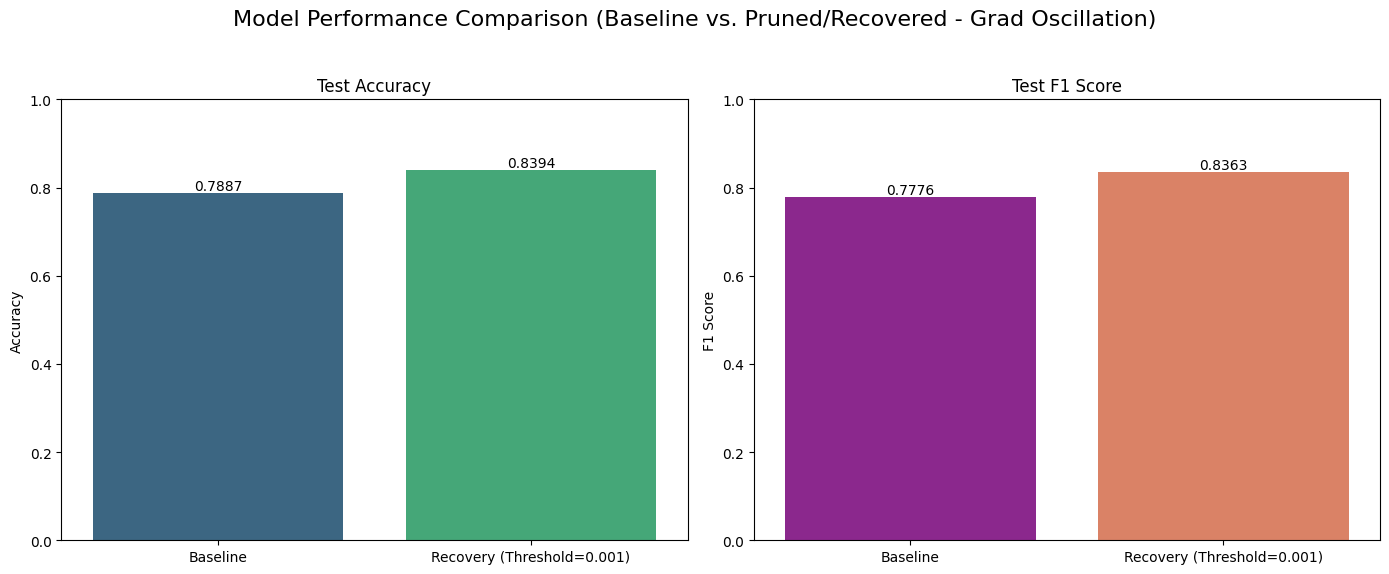

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter out the elapsed time and retention ratio for plotting
plot_data = [res for res in results if 'Model' in res]
df_results = pd.DataFrame(plot_data)

# Create a more descriptive label for the models
df_results['Model_Label'] = df_results.apply(lambda row: f"Baseline" if row['Model'] == 'Baseline' else f"Recovery (Threshold={row['Threshold']})", axis=1)

# Set up the matplotlib figure and axes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Model Performance Comparison (Baseline vs. Pruned/Recovered - Grad Oscillation)', fontsize=16)

# Plot Test Accuracy
sns.barplot(x='Model_Label', y='Test Accuracy', data=df_results, ax=axes[0], palette='viridis', hue='Model_Label', legend=False)
axes[0].set_title('Test Accuracy')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1) # Set y-limit from 0 to 1 for accuracy
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f')

# Plot Test F1
sns.barplot(x='Model_Label', y='Test F1', data=df_results, ax=axes[1], palette='plasma', hue='Model_Label', legend=False)
axes[1].set_title('Test F1 Score')
axes[1].set_ylabel('F1 Score')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1) # Set y-limit from 0 to 1 for F1 score
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.4f')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
plt.show()

### Perbandingan Akurasi Tes: Baseline vs. Pemulihan (Gradien Osilasi)

Berikut adalah plot batang yang membandingkan Akurasi Tes model Baseline dengan model Pemulihan setelah pemangkasan menggunakan metode `grad_oscillation`.

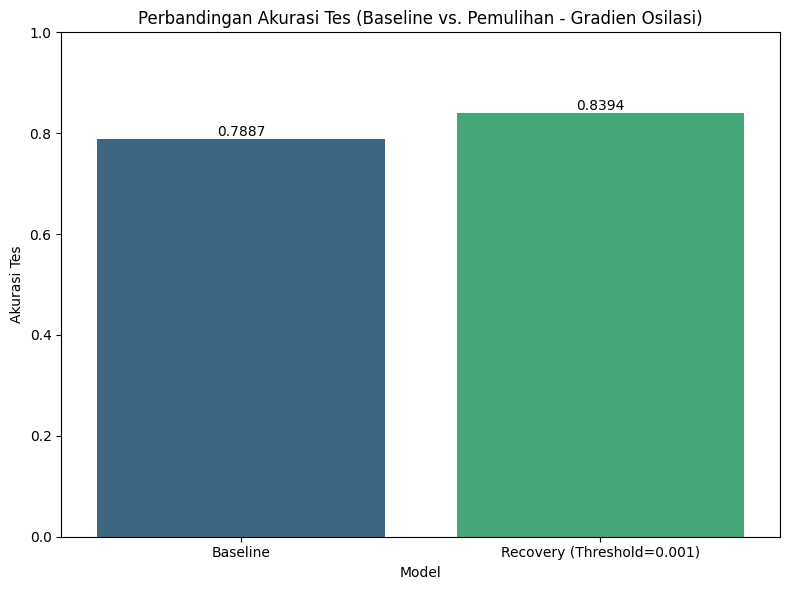

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter out the elapsed time and retention ratio for plotting
plot_data = [res for res in results if 'Model' in res]
df_results = pd.DataFrame(plot_data)

# Create a more descriptive label for the models
df_results['Model_Label'] = df_results.apply(lambda row: f"Baseline" if row['Model'] == 'Baseline' else f"Recovery (Threshold={row['Threshold']})", axis=1)

plt.figure(figsize=(8, 6))
sns.barplot(x='Model_Label', y='Test Accuracy', data=df_results, palette='viridis', hue='Model_Label', legend=False)
plt.title('Perbandingan Akurasi Tes (Baseline vs. Pemulihan - Gradien Osilasi)')
plt.ylabel('Akurasi Tes')
plt.xlabel('Model')
plt.ylim(0, 1) # Set y-limit from 0 to 1 for accuracy
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.4f')
plt.tight_layout()
plt.show()

### Visualize Token Importance Score Distribution

To better understand the calculated token importance scores, let's visualize their distribution using a histogram. This will show us how many tokens fall within different ranges of importance.

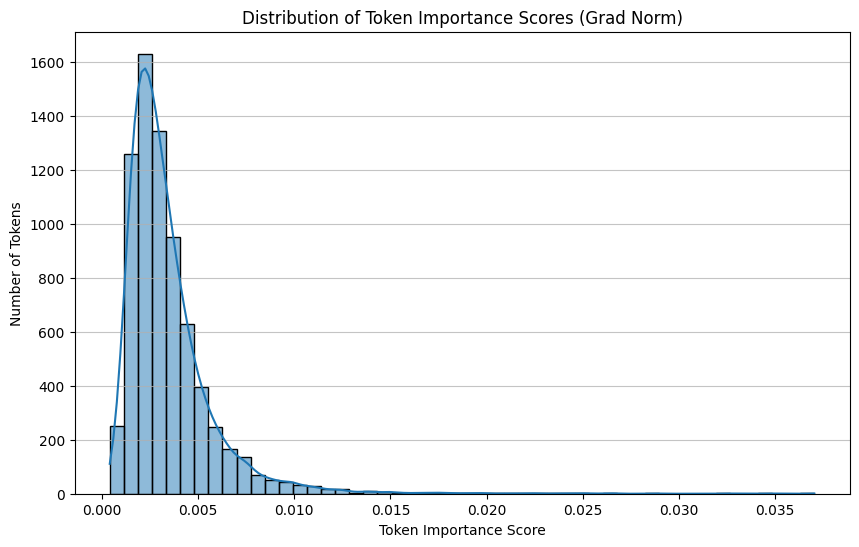

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the scores from the dictionary
scores = list(token_importance_scores.values())

plt.figure(figsize=(10, 6))
sns.histplot(scores, bins=50, kde=True)
plt.title('Distribution of Token Importance Scores (Grad Norm)')
plt.xlabel('Token Importance Score')
plt.ylabel('Number of Tokens')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Visualize Token Importance Score Distribution (Grad Oscillation)

Let's visualize the distribution of token importance scores calculated using the `grad_oscillation` method. This will help us understand the variability of gradients for different tokens.

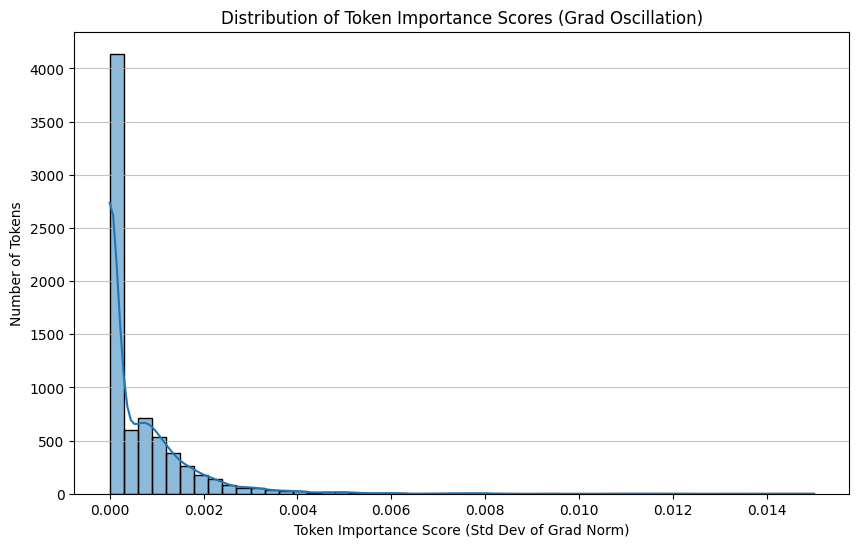

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the scores from the dictionary
scores_oscillation = list(token_importance_scores.values())

plt.figure(figsize=(10, 6))
sns.histplot(scores_oscillation, bins=50, kde=True)
plt.title('Distribution of Token Importance Scores (Grad Oscillation)')
plt.xlabel('Token Importance Score (Std Dev of Grad Norm)')
plt.ylabel('Number of Tokens')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Visualisasi Skor Osilasi Gradien per Token

Untuk lebih jelas melihat variabilitas 'naik turun' dari skor osilasi gradien di antara token-token yang berbeda, mari kita plot skor ini sebagai scatter plot.

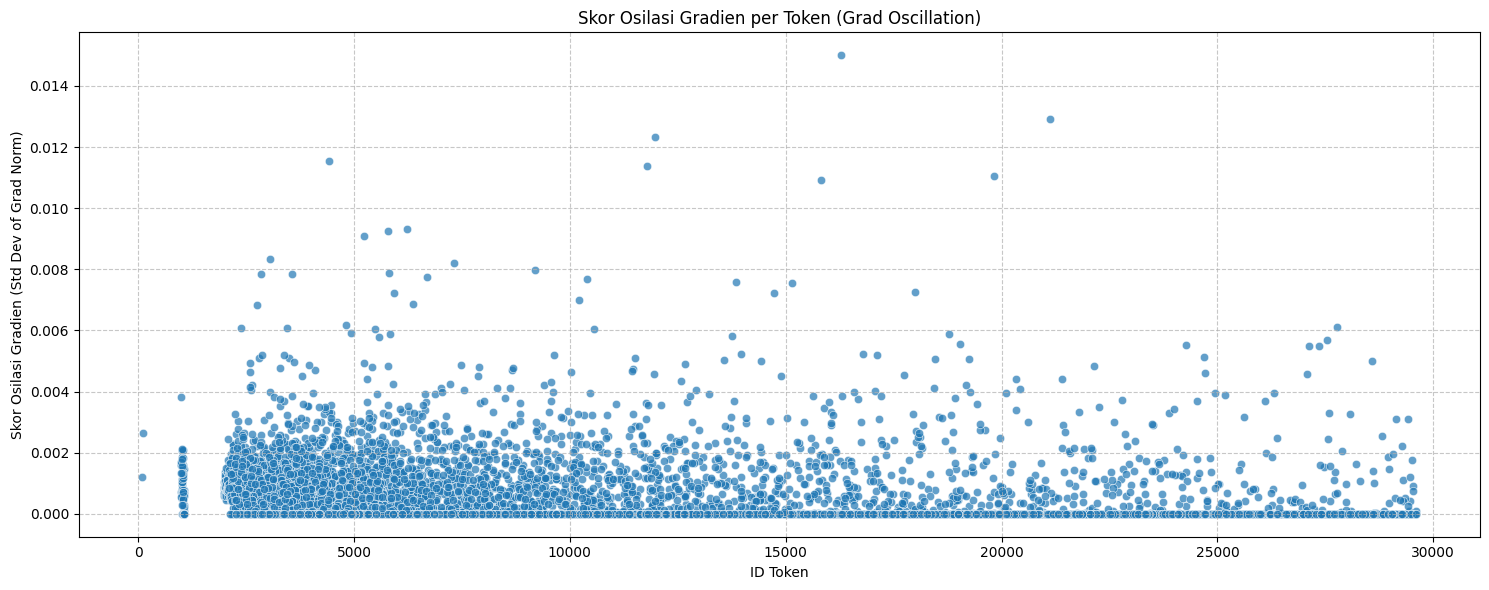

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract token IDs and their oscillation scores
token_ids = list(token_importance_scores.keys())
oscillation_scores = list(token_importance_scores.values())

plt.figure(figsize=(15, 6))
sns.scatterplot(x=token_ids, y=oscillation_scores, alpha=0.7)
plt.title('Skor Osilasi Gradien per Token (Grad Oscillation)')
plt.xlabel('ID Token')
plt.ylabel('Skor Osilasi Gradien (Std Dev of Grad Norm)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Visualisasi Skor Osilasi Gradien per Token (Grafik Garis)

Mari kita visualisasikan skor osilasi gradien per token menggunakan grafik garis untuk menekankan pola 'naik turun' dari variabilitas gradien.

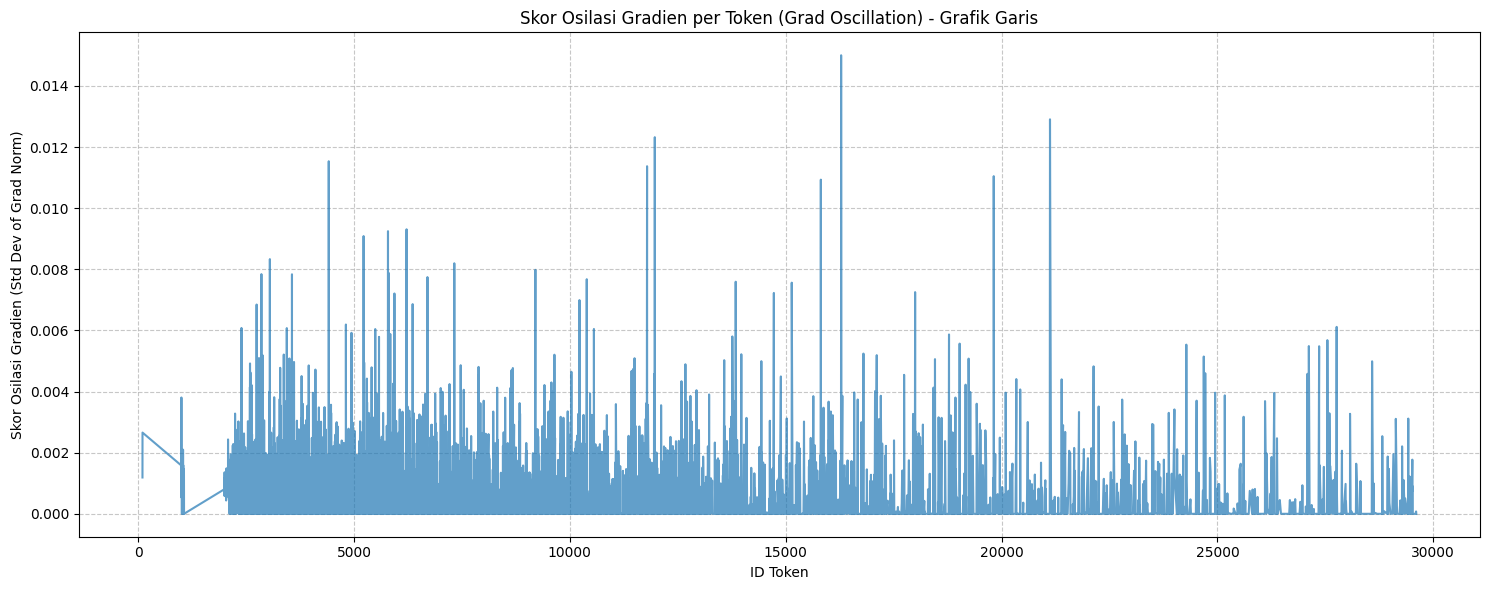

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract token IDs and their oscillation scores (already available from previous cells)
# token_ids = list(token_importance_scores.keys())
# oscillation_scores = list(token_importance_scores.values())

plt.figure(figsize=(15, 6))
sns.lineplot(x=token_ids, y=oscillation_scores, alpha=0.7)
plt.title('Skor Osilasi Gradien per Token (Grad Oscillation) - Grafik Garis')
plt.xlabel('ID Token')
plt.ylabel('Skor Osilasi Gradien (Std Dev of Grad Norm)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Implement Token Pruning

Now that we have the token importance scores, we can implement the pruning logic. This involves:
1. **Identifying tokens to prune:** Based on a defined `THRESHOLD`, tokens with importance scores below this value will be marked for pruning.
2. **Masking pruned tokens:** In the dataset, these identified tokens will be replaced with the `[MASK]` token (`tokenizer.mask_token_id`).
3. **Creating a pruned DataLoader:** New DataLoaders will be created from the modified datasets for recovery fine-tuning.

In [9]:
def prune_tokens(token_importance_scores, threshold, tokenizer):
    """
    Identifies tokens to prune based on importance scores and a threshold.
    Returns a set of token IDs to be pruned.
    """
    # Filter out special tokens like [CLS], [SEP], [PAD] from pruning consideration
    # These are usually important for sentence structure or padding and should not be pruned based on importance scores.
    special_tokens_ids = set(tokenizer.all_special_ids)

    tokens_to_prune = set()
    for token_id, score in token_importance_scores.items():
        if token_id not in special_tokens_ids and score < threshold:
            tokens_to_prune.add(token_id)
    return tokens_to_prune

def mask_tokens_in_batch(examples, tokens_to_prune, tokenizer):
    """
    Replaces tokens identified for pruning with the [MASK] token in a batch of examples.
    """
    updated_input_ids = []
    for input_id_list in examples['input_ids']:
        updated_list = []
        for token_id in input_id_list:
            if token_id in tokens_to_prune:
                updated_list.append(tokenizer.mask_token_id)
            else:
                updated_list.append(token_id)
        updated_input_ids.append(updated_list)
    examples['input_ids'] = updated_input_ids
    return examples


# --- Apply pruning for each threshold ---
pruned_dataloaders = {}

for threshold in THRESHOLDS:
    print(f"\n--- Applying pruning with threshold: {threshold} ---")
    tokens_to_prune = prune_tokens(token_importance_scores, threshold, tokenizer)
    print(f"Number of tokens to prune: {len(tokens_to_prune)}")

    # Apply masking to the datasets
    pruned_train_dataset = train_dataset.map(
        lambda examples: mask_tokens_in_batch(examples, tokens_to_prune, tokenizer),
        batched=True,
        load_from_cache_file=False # Recalculate each time
    )
    pruned_val_dataset = val_dataset.map(
        lambda examples: mask_tokens_in_batch(examples, tokens_to_prune, tokenizer),
        batched=True,
        load_from_cache_file=False # Recalculate each time
    )

    # Create new DataLoaders for pruned datasets
    pruned_train_loader = DataLoader(pruned_train_dataset, batch_size=BATCH_TRAIN, shuffle=True)
    pruned_val_loader = DataLoader(pruned_val_dataset, batch_size=BATCH_TEST)

    pruned_dataloaders[threshold] = {
        'train': pruned_train_loader,
        'val': pruned_val_loader
    }

    print(f"Pruned train samples: {len(pruned_train_dataset)}")
    print(f"Pruned validation samples: {len(pruned_val_dataset)}")


--- Applying pruning with threshold: 0.001 ---
Number of tokens to prune: 150


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Pruned train samples: 500
Pruned validation samples: 50


In [26]:
!pip install --upgrade datasets huggingface_hub
# After this cell executes, please restart the Colab runtime (Runtime -> Restart runtime) and then re-run your notebook cells.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.4/693.4 kB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 22.1 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.18.0
    Uninstalling huggingface_hub-1.18.0:
      Successfully uninstalled huggingface_hub-1.18.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


In [17]:
from huggingface_hub import HfFileSystem
import logging

# Configure logging to see more details from huggingface_hub
logging.basicConfig(level=logging.INFO)
logging.getLogger('huggingface_hub').setLevel(logging.INFO)

hfs = HfFileSystem()

try:
    # Try to resolve the path for 'imdb' as a dataset
    # This mimics what `datasets` might do internally but gives us more control
    resolved_path = hfs.resolve_path(f"datasets/{TASK_NAME}")
    print(f"Resolved path for datasets/{TASK_NAME}: {resolved_path}")
except Exception as e:
    print(f"Error resolving path for datasets/{TASK_NAME}: {e}")
    print("This suggests that 'datasets/imdb' might not be the correct format or that there's an issue with how the hub is being accessed.")

try:
    # Try to resolve the path for 'imdb' directly (without 'datasets/' prefix)
    resolved_path_direct = hfs.resolve_path(f"{TASK_NAME}")
    print(f"Resolved path for {TASK_NAME} (direct): {resolved_path_direct}")
except Exception as e:
    print(f"Error resolving path for {TASK_NAME} (direct): {e}")
    print("This confirms 'imdb' alone is not being recognized as a valid repo ID by huggingface_hub in this context.")


print("\nAttempting to list files for 'imdb' dataset to understand its structure on the Hub.")
try:
    # List files for 'imdb' under 'datasets' namespace if it exists
    imdb_files = hfs.ls('datasets/imdb', detail=False)
    print(f"Files in datasets/imdb: {imdb_files[:5]}...") # Print first 5 files
except Exception as e:
    print(f"Could not list files for 'datasets/imdb': {e}")

try:
    # List files for 'imdb' as a direct repo
    imdb_files_direct = hfs.ls('imdb', detail=False)
    print(f"Files in imdb (direct): {imdb_files_direct[:5]}...") # Print first 5 files
except Exception as e:
    print(f"Could not list files for 'imdb' directly: {e}")


Error resolving path for datasets/imdb: Invalid HF URI 'hf://datasets/imdb'. Repository id must be 'namespace/name', got 'imdb'. 
This suggests that 'datasets/imdb' might not be the correct format or that there's an issue with how the hub is being accessed.
Error resolving path for imdb (direct): Repository id must be 'namespace/name', got 'imdb'. Single-segment ids (e.g. 'gpt2') are no longer supported.
This confirms 'imdb' alone is not being recognized as a valid repo ID by huggingface_hub in this context.

Attempting to list files for 'imdb' dataset to understand its structure on the Hub.
Could not list files for 'datasets/imdb': Invalid HF URI 'hf://datasets/imdb'. Repository id must be 'namespace/name', got 'imdb'. 
Could not list files for 'imdb' directly: Repository id must be 'namespace/name', got 'imdb'. Single-segment ids (e.g. 'gpt2') are no longer supported.
